In [4]:
import sys
from pathlib import Path

current_dir = Path.cwd()
project_root = current_dir.parent
sys.path.insert(0, str(project_root))

from config.config import (
    POSITION_KPIS,
    MISSING_THRESHOLD,
    TMV_DELTA_THRESHOLD,
    MIN_MINUTES_CUTOFF
)

from helper_functions_regression.tmv_helpers import (
    process_single_position,
    run_logistic_regression_analysis
)

--- Processing Position: Centre back ---
1. Loading & Filtering...
2. Linking Seasons...
3. Cleaning (Min Minutes: 300)...
4. Imputing & Labeling (Threshold: 50000)...
5. Removing Collinear Features (Threshold: 0.9)...

--- Checking Collinearity (Threshold: 0.9) ---


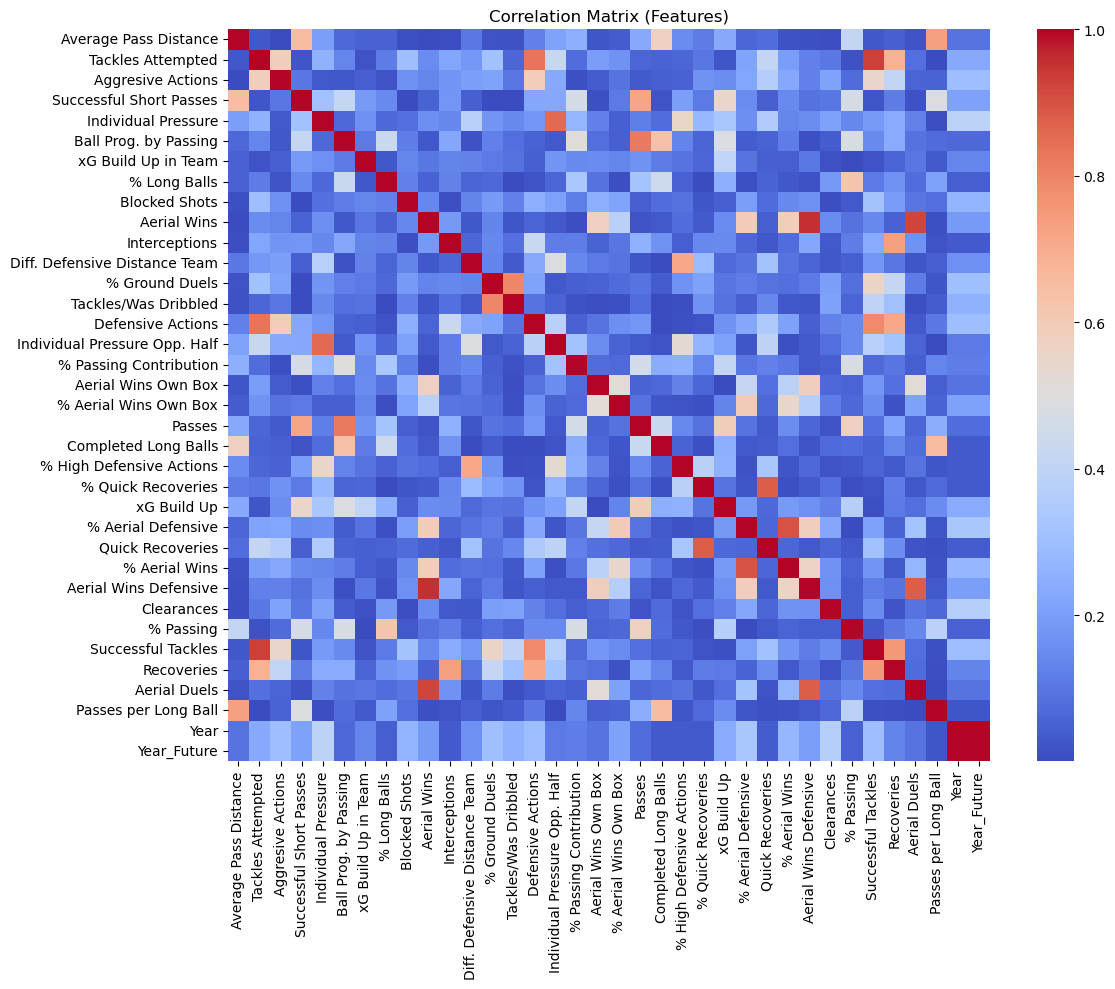

Detected 4 collinear features to remove: ['Aerial Wins Defensive', 'Successful Tackles', 'Aerial Duels', 'Year_Future']
6. Saved clean dataset to: regr_Centre_back.csv
   Final shape: (839, 38)

--- Running Logistic Regression Analysis ---
                              Logit Regression Results                              
Dep. Variable:     Significant_tmv_increase   No. Observations:                  839
Model:                                Logit   Df Residuals:                      807
Method:                                 MLE   Df Model:                           31
Date:                      Mon, 26 Jan 2026   Pseudo R-squ.:                 0.05869
Time:                              12:27:08   Log-Likelihood:                -527.21
converged:                             True   LL-Null:                       -560.08
Covariance Type:                  nonrobust   LLR p-value:                 0.0002695
                                    coef    std err          z      P>|z|      [

In [5]:
df_cb = process_single_position(
    position_name="Centre back",
    project_root=project_root,       # <--- Pass path
    kpi_dict=POSITION_KPIS,          # <--- Pass Dict
    missing_threshold=MISSING_THRESHOLD, # <--- Pass Constant
    tmv_threshold=TMV_DELTA_THRESHOLD,   # <--- Pass Constant
    min_minutes=MIN_MINUTES_CUTOFF       # <--- Pass Constant
)

run_logistic_regression_analysis(df_cb)